# Chapter 12: Cross-Validation and Model Evaluation Techniques

**Book:** scikit-learn Cookbook, Third Edition  
**Author:** John Sukup  
**Publisher:** Packt Publishing

## Learning Objectives

1. Understand cross-validation and its purpose.
2. Apply K-Fold and Stratified K-Fold cross-validation.
3. Explore advanced cross-validation methods.
4. Evaluate models using multiple performance metrics.
5. Implement cross-validation with scikit-learn.
6. Tune model hyperparameters using GridSearchCV.
7. Evaluate model generalizability using learning and validation curves.

## Chapter Contents

1. Introduction to Cross-Validation
2. Advanced Cross-Validation Methods
3. Model Evaluation Metrics Overview
4. Implementing Cross-Validation in scikit-learn
5. Model Selection Techniques
6. Evaluating Model Generalizability
7. Practical Exercises
8. Summary

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification, load_diabetes
from sklearn.model_selection import (
    KFold,
    StratifiedKFold,
    LeaveOneOut,
    cross_val_score,
    cross_validate,
    GridSearchCV,
    learning_curve,
    validation_curve,
    train_test_split
)
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

print("Libraries imported successfully!")

## 1. Introduction to Cross-Validation

Cross-validation is a technique for estimating how well a machine
learning model performs on unseen data.

Instead of evaluating a model using only one train-test split,
cross-validation repeatedly divides the dataset into training and
validation subsets.

### K-Fold Cross-Validation

The dataset is divided into K folds. Each fold is used once as the
validation set while the remaining folds are used for training.

The final score is commonly calculated as the average score across
all folds.

### Stratified K-Fold

Stratified K-Fold attempts to preserve the class proportions in
each fold. This is especially useful for classification problems
where the target classes are imbalanced.

Cross-validation provides a more comprehensive estimate than relying
on a single split, although the estimate still depends on the dataset,
the splitting strategy, and the chosen evaluation metric.

In [7]:
X, y = make_classification(
    n_samples=500,
    n_features=10,
    n_informative=8,
    n_redundant=2,
    n_classes=2,
    random_state=2024
)

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("\nClass distribution:")
print(pd.Series(y).value_counts().sort_index())

Feature matrix shape: (500, 10)
Target shape: (500,)

Class distribution:
0    250
1    250
Name: count, dtype: int64


In [8]:
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=2024
)

model = LogisticRegression(max_iter=1000)
kf_scores = []

for fold, (train_idx, val_idx) in enumerate(kf.split(X), start=1):
    X_train_fold, X_val_fold = X[train_idx], X[val_idx]
    y_train_fold, y_val_fold = y[train_idx], y[val_idx]

    model.fit(X_train_fold, y_train_fold)
    y_pred_fold = model.predict(X_val_fold)

    score = accuracy_score(y_val_fold, y_pred_fold)
    kf_scores.append(score)

    print(f"Fold {fold} accuracy: {score:.3f}")

print(f"\nMean K-Fold accuracy: {np.mean(kf_scores):.3f}")

Fold 1 accuracy: 0.720
Fold 2 accuracy: 0.720
Fold 3 accuracy: 0.880
Fold 4 accuracy: 0.710
Fold 5 accuracy: 0.750

Mean K-Fold accuracy: 0.756


In [9]:
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=2024
)

skf_scores = []

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y), start=1):
    X_train_fold, X_val_fold = X[train_idx], X[val_idx]
    y_train_fold, y_val_fold = y[train_idx], y[val_idx]

    model.fit(X_train_fold, y_train_fold)
    y_pred_fold = model.predict(X_val_fold)

    score = accuracy_score(y_val_fold, y_pred_fold)
    skf_scores.append(score)

    print(f"Fold {fold} accuracy: {score:.3f}")

print(f"\nMean Stratified K-Fold accuracy: {np.mean(skf_scores):.3f}")

Fold 1 accuracy: 0.790
Fold 2 accuracy: 0.760
Fold 3 accuracy: 0.760
Fold 4 accuracy: 0.760
Fold 5 accuracy: 0.760

Mean Stratified K-Fold accuracy: 0.766


,Fold,K-Fold Accuracy,Stratified K-Fold Accuracy
0,1,0.72,0.79
1,2,0.72,0.76
2,3,0.88,0.76
3,4,0.71,0.76
4,5,0.75,0.76


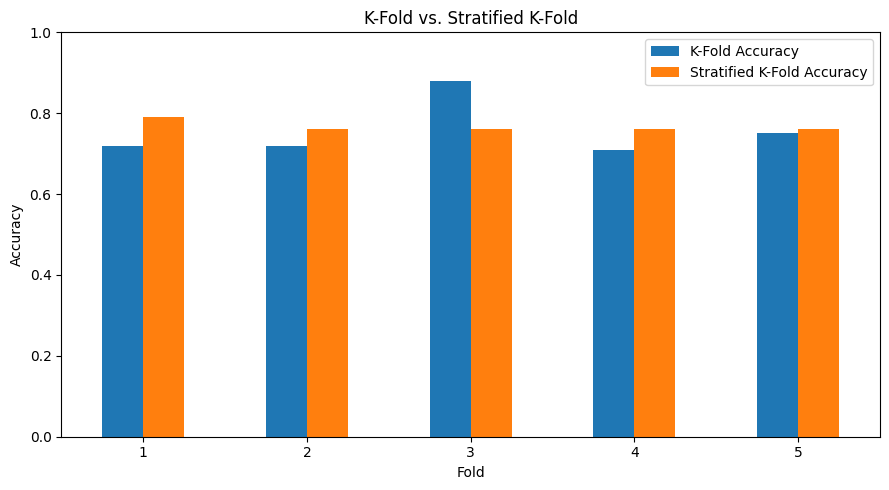

In [10]:
cv_comparison = pd.DataFrame({
    "Fold": range(1, 6),
    "K-Fold Accuracy": kf_scores,
    "Stratified K-Fold Accuracy": skf_scores
})

display(cv_comparison.round(3))

cv_comparison.set_index("Fold").plot(
    kind="bar",
    figsize=(9, 5)
)

plt.ylabel("Accuracy")
plt.title("K-Fold vs. Stratified K-Fold")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### How It Works

K-Fold evaluates a model using multiple train-validation splits.
Each fold produces an accuracy score, and the mean score summarizes
the model's performance across those splits.

Stratified K-Fold preserves the approximate class proportions in
each fold, which can make the evaluation more representative when
class distributions are uneven.

The bar chart compares the scores from both approaches. Small
differences are expected because the validation subsets differ.

A higher score in one cross-validation strategy does not automatically
mean that it is always superior. The splitting method should match
the structure and purpose of the dataset.

## 2. Advanced Cross-Validation Methods

Advanced cross-validation methods provide additional ways to evaluate
models and tune hyperparameters.

### Leave-One-Out Cross-Validation (LOOCV)

LOOCV uses one observation as the validation set and all remaining
observations as training data. The process repeats for every observation.

It makes extensive use of the available data for training, but can be
computationally expensive for large datasets.

### Nested Cross-Validation

Nested cross-validation separates hyperparameter selection from
performance estimation.

- The inner loop selects model hyperparameters.
- The outer loop evaluates the selected model on held-out data.

This reduces the risk of reporting an overly optimistic score after
repeatedly tuning a model on the same validation data.

The appropriate method depends on dataset size, computational cost,
and the reliability required from the performance estimate.

In [15]:
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.model_selection import LeaveOneOut, cross_val_score
from sklearn.linear_model import Ridge

# Load dataset
diabetes = load_diabetes()
X_diabetes = diabetes.data
y_diabetes = diabetes.target

# Run Leave-One-Out Cross-Validation
loo = LeaveOneOut()
model = Ridge(alpha=1.0)

loo_scores = cross_val_score(
    model,
    X_diabetes,
    y_diabetes,
    cv=loo,
    scoring="neg_mean_squared_error"
)

loo_mse = -loo_scores

print("Number of LOOCV evaluations:", len(loo_scores))
print("Mean LOOCV MSE:", round(np.mean(loo_mse), 3))
print("Standard deviation of MSE:", round(np.std(loo_mse), 3))

Number of LOOCV evaluations: 442
Mean LOOCV MSE: 3327.655
Standard deviation of MSE: 3845.556


In [16]:
from sklearn.model_selection import cross_val_score, GridSearchCV
from sklearn.pipeline import make_pipeline

ridge_pipeline = make_pipeline(
    StandardScaler(),
    Ridge()
)

param_grid = {
    "ridge__alpha": [0.01, 0.1, 1.0, 10.0, 100.0]
}

inner_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=2024
)

outer_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=2025
)

grid_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=param_grid,
    scoring="neg_mean_squared_error",
    cv=inner_cv
)

nested_scores = cross_val_score(
    grid_search,
    X_diabetes,
    y_diabetes,
    scoring="neg_mean_squared_error",
    cv=outer_cv
)

print("Nested CV mean MSE:", round(-np.mean(nested_scores), 3))
print("Nested CV standard deviation:", round(np.std(nested_scores), 3))

Nested CV mean MSE: 2987.867
Nested CV standard deviation: 325.937


### How It Works

LOOCV evaluates a model once for every observation. In the diabetes
example, the number of evaluations equals the number of observations.

Nested cross-validation evaluates the model-selection process itself.
GridSearchCV selects the alpha parameter using the inner folds, while
the outer folds estimate performance on held-out observations.

The nested approach is useful when hyperparameter tuning could
otherwise make the evaluation score too optimistic.

Both methods can be computationally expensive. The additional cost
should be considered when selecting a validation strategy.

## 3. Model Evaluation Metrics Overview

Evaluation metrics quantify different aspects of model performance.

### Accuracy
The proportion of predictions that are correct.

### Precision
The proportion of positive predictions that are correct.

### Recall
The proportion of actual positive observations correctly identified.

### F1-score
The harmonic mean of precision and recall.

### Mean Squared Error (MSE)
The average squared difference between regression predictions
and the observed target values.

### Why Multiple Metrics Matter

Accuracy may be misleading when classes are imbalanced. Precision
and recall are useful when false positives and false negatives have
different consequences.

For regression, metrics such as MSE measure prediction error rather
than classification correctness.

The metric should be chosen according to the problem and the cost
of different types of errors.

Accuracy: 0.82
Precision: 0.767
Recall: 0.92
F1-score: 0.836

Classification report:
              precision    recall  f1-score   support

           0       0.90      0.72      0.80        50
           1       0.77      0.92      0.84        50

    accuracy                           0.82       100
   macro avg       0.83      0.82      0.82       100
weighted avg       0.83      0.82      0.82       100



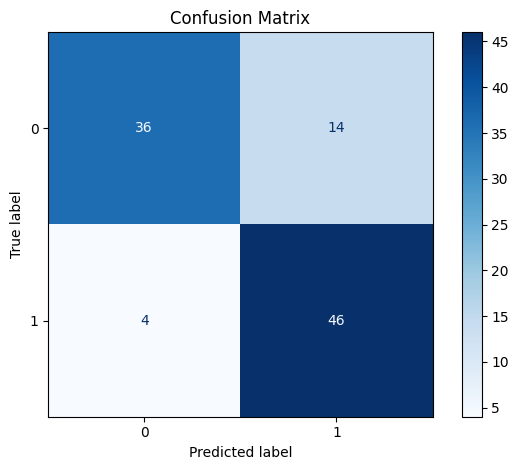

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=2024,
    stratify=y
)

evaluation_model = LogisticRegression(max_iter=1000)
evaluation_model.fit(X_train, y_train)

y_pred = evaluation_model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall:", round(recall_score(y_test, y_pred), 3))
print("F1-score:", round(f1_score(y_test, y_pred), 3))

print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Blues"
)

plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

### How It Works

The model is trained on the training subset and evaluated on the
held-out testing subset.

Accuracy summarizes the overall proportion of correct predictions.
Precision measures the reliability of positive predictions, while
recall measures how many positive cases were detected.

F1-score combines precision and recall into a single measure.
The confusion matrix displays correct and incorrect predictions
for each class.

These metrics should be considered together rather than relying
on accuracy alone, especially when the target classes are imbalanced.

In [18]:
X_cv, y_cv = make_classification(
    n_samples=500,
    n_features=10,
    weights=[0.7, 0.3],
    random_state=2024
)

model_cv = LogisticRegression(max_iter=1000)

scores = cross_val_score(
    model_cv,
    X_cv,
    y_cv,
    cv=5,
    scoring="accuracy"
)

print("Cross-validation scores:", np.round(scores, 3))
print(f"Mean accuracy: {np.mean(scores):.3f}")

Cross-validation scores: [0.87 0.92 0.87 0.95 0.94]
Mean accuracy: 0.910


In [19]:
results = cross_validate(
    model_cv,
    X_cv,
    y_cv,
    cv=5,
    scoring=["accuracy", "precision", "recall", "f1"]
)

print(f"Mean accuracy: {np.mean(results['test_accuracy']):.3f}")
print(f"Mean precision: {np.mean(results['test_precision']):.3f}")
print(f"Mean recall: {np.mean(results['test_recall']):.3f}")
print(f"Mean F1: {np.mean(results['test_f1']):.3f}")

Mean accuracy: 0.910
Mean precision: 0.875
Mean recall: 0.820
Mean F1: 0.845


### How It Works

`cross_val_score()` evaluates a model using one scoring metric
across multiple validation folds.

`cross_validate()` supports multiple metrics and can return
additional timing information.

Both functions simplify the validation workflow and reduce the
need to manually create training and validation loops.

The returned scores allow us to examine both average performance
and variation between folds.

## 5. Model Selection Techniques

Model selection involves choosing a model configuration that
performs well on unseen data.

Hyperparameters are settings chosen before or during model selection,
rather than values learned directly from the training examples.

Examples include:

- Regularization strength.
- Tree depth.
- Number of neighbors.
- Kernel parameters.

GridSearchCV evaluates specified combinations of hyperparameters
using cross-validation and selects the best combination according
to a chosen scoring metric.

Hyperparameter tuning should be performed without using the final
test set. The test set should remain reserved for final evaluation.

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X_cv,
    y_cv,
    test_size=0.2,
    random_state=2024,
    stratify=y_cv
)

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(max_iter=2000))
])

param_grid = {
    "logistic__C": [0.01, 0.1, 1, 10, 100],
    "logistic__solver": ["lbfgs"]
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="accuracy",
    cv=5,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best CV accuracy:", round(grid_search.best_score_, 3))

best_model = grid_search.best_estimator_
test_predictions = best_model.predict(X_test)

print("Test accuracy:", round(
    accuracy_score(y_test, test_predictions), 3
))

Best parameters: {'logistic__C': 0.1, 'logistic__solver': 'lbfgs'}
Best CV accuracy: 0.908
Test accuracy: 0.92


,param_logistic__C,mean_test_score,std_test_score
0,0.01,0.8600,0.049624
1,0.10,0.9075,0.047170
2,1.00,0.9025,0.045689
3,10.00,0.9075,0.043012
4,100.00,0.9075,0.043012


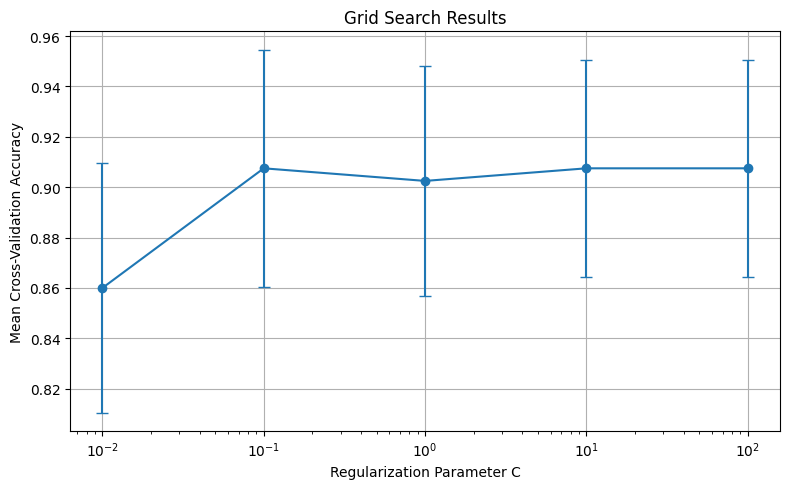

In [21]:
grid_results = pd.DataFrame(grid_search.cv_results_)

grid_plot = grid_results[
    ["param_logistic__C", "mean_test_score", "std_test_score"]
].copy()

grid_plot["param_logistic__C"] = (
    grid_plot["param_logistic__C"].astype(float)
)

display(grid_plot)

plt.figure(figsize=(8, 5))

plt.errorbar(
    grid_plot["param_logistic__C"],
    grid_plot["mean_test_score"],
    yerr=grid_plot["std_test_score"],
    marker="o",
    capsize=4
)

plt.xscale("log")
plt.xlabel("Regularization Parameter C")
plt.ylabel("Mean Cross-Validation Accuracy")
plt.title("Grid Search Results")
plt.grid(True)
plt.tight_layout()
plt.show()

### How It Works

GridSearchCV evaluates the combinations defined in `param_grid`
using cross-validation on the training data.

The `C` parameter controls the inverse strength of regularization
in Logistic Regression. Smaller values apply stronger regularization,
while larger values apply weaker regularization.

The best parameters are selected using the mean cross-validation
score. The selected model is then evaluated on the separate test set.

The test score provides an estimate of performance on unseen data,
provided that the test set has not been used to select or tune
the model.

## 6. Evaluating Model Generalizability

Generalizability describes how well a model performs on new data
that was not used during training.

### Learning Curve

A learning curve shows how training and validation performance
change as the amount of training data increases.

- A large gap between training and validation scores can indicate
  overfitting.
- Low scores for both can indicate underfitting.
- Converging scores with good performance can indicate better
  generalization.

### Validation Curve

A validation curve shows how model performance changes with a
particular hyperparameter.

For Logistic Regression, the regularization parameter C can affect
model complexity and generalization.

Learning and validation curves help diagnose model behavior, but
their conclusions should be considered together with the evaluation
metric and the characteristics of the dataset.

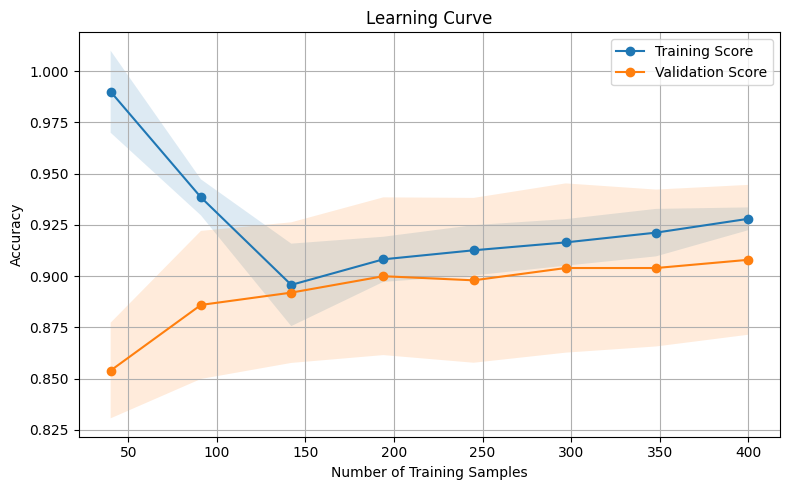

In [22]:
from sklearn.model_selection import learning_curve

learning_sizes, train_scores, validation_scores = learning_curve(
    estimator=Pipeline([
        ("scaler", StandardScaler()),
        ("logistic", LogisticRegression(max_iter=2000))
    ]),
    X=X_cv,
    y=y_cv,
    cv=5,
    scoring="accuracy",
    train_sizes=np.linspace(0.1, 1.0, 8),
    n_jobs=-1
)

train_mean = train_scores.mean(axis=1)
train_std = train_scores.std(axis=1)

validation_mean = validation_scores.mean(axis=1)
validation_std = validation_scores.std(axis=1)

plt.figure(figsize=(8, 5))

plt.plot(
    learning_sizes,
    train_mean,
    marker="o",
    label="Training Score"
)

plt.fill_between(
    learning_sizes,
    train_mean - train_std,
    train_mean + train_std,
    alpha=0.15
)

plt.plot(
    learning_sizes,
    validation_mean,
    marker="o",
    label="Validation Score"
)

plt.fill_between(
    learning_sizes,
    validation_mean - validation_std,
    validation_mean + validation_std,
    alpha=0.15
)

plt.xlabel("Number of Training Samples")
plt.ylabel("Accuracy")
plt.title("Learning Curve")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

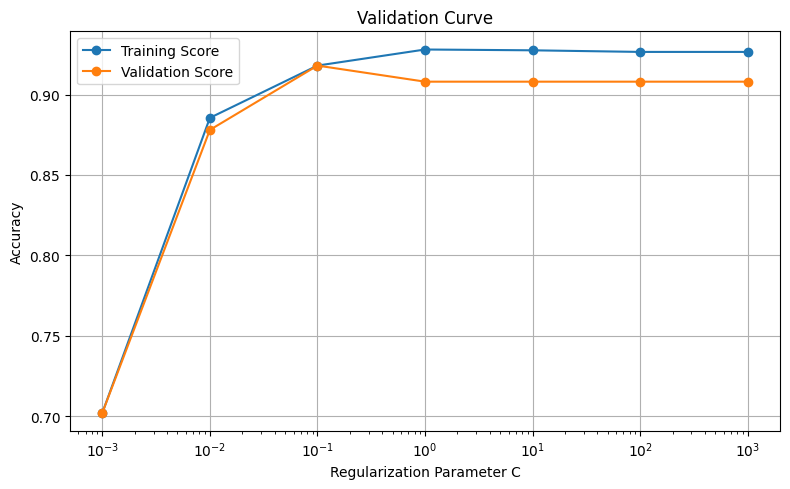

In [23]:
from sklearn.model_selection import validation_curve

C_values = np.logspace(-3, 3, 7)

validation_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(max_iter=2000))
])

train_scores, val_scores = validation_curve(
    estimator=validation_pipeline,
    X=X_cv,
    y=y_cv,
    param_name="logistic__C",
    param_range=C_values,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

train_mean = train_scores.mean(axis=1)
val_mean = val_scores.mean(axis=1)

plt.figure(figsize=(8, 5))

plt.plot(
    C_values,
    train_mean,
    marker="o",
    label="Training Score"
)

plt.plot(
    C_values,
    val_mean,
    marker="o",
    label="Validation Score"
)

plt.xscale("log")
plt.xlabel("Regularization Parameter C")
plt.ylabel("Accuracy")
plt.title("Validation Curve")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### How It Works

The learning curve compares training and validation performance
across increasing training-set sizes.

A large gap between the two curves may indicate overfitting.
If both curves remain low, the model may be underfitting.

The validation curve evaluates different values of the regularization
parameter C. Small C values apply stronger regularization, while
large values apply weaker regularization.

These curves help identify useful model configurations and show
whether additional training data or hyperparameter tuning may help.

The exact conclusions depend on the observed curves and should not
be assumed before the plots are examined.

In [24]:
exercise_scores = cross_validate(
    LogisticRegression(max_iter=1000),
    X_cv,
    y_cv,
    cv=5,
    scoring=["accuracy", "precision", "recall", "f1"]
)

exercise_1_results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Mean Score": [
        exercise_scores["test_accuracy"].mean(),
        exercise_scores["test_precision"].mean(),
        exercise_scores["test_recall"].mean(),
        exercise_scores["test_f1"].mean()
    ]
})

display(exercise_1_results.round(3))

,Metric,Mean Score
0,Accuracy,0.910
1,Precision,0.875
2,Recall,0.820
3,F1-score,0.845


In [25]:
exercise_grid = GridSearchCV(
    LogisticRegression(max_iter=2000),
    param_grid={
        "C": [0.01, 0.1, 1, 10, 100]
    },
    scoring="accuracy",
    cv=5,
    n_jobs=-1
)

exercise_grid.fit(X_train, y_train)

print("Best C:", exercise_grid.best_params_["C"])
print("Best CV accuracy:", round(exercise_grid.best_score_, 3))

exercise_test_predictions = exercise_grid.predict(X_test)

print(
    "Test accuracy:",
    round(
        accuracy_score(y_test, exercise_test_predictions),
        3
    )
)

Best C: 0.1
Best CV accuracy: 0.91
Test accuracy: 0.92


### Exercise 3: Assessing Model Generalization

Review the learning curve and validation curve produced earlier.

Answer the following questions:

1. Does the training score differ substantially from the validation score?
2. Does validation performance improve as more training data is used?
3. Which values of C provide competitive validation performance?
4. Is there evidence of underfitting or overfitting?
5. What additional experiment would help confirm your conclusion?

Base the answers on the curves generated by your notebook. Avoid
claiming that a model overfits or underfits unless the results support it.

## 7. Summary

Chapter 12 introduced methods for evaluating machine learning models
and estimating their performance on unseen data.

The main concepts covered were:

1. **K-Fold Cross-Validation:** Divides data into multiple folds
   and evaluates the model repeatedly.
2. **Stratified K-Fold:** Attempts to preserve class proportions
   across validation folds.
3. **Advanced Cross-Validation:** LOOCV and nested cross-validation
   provide alternative validation strategies.
4. **Evaluation Metrics:** Accuracy, precision, recall, F1-score,
   and regression error metrics measure different aspects of performance.
5. **Cross-Validation APIs:** `cross_val_score()` and
   `cross_validate()` simplify repeated evaluation.
6. **Model Selection:** GridSearchCV selects hyperparameters using
   cross-validation.
7. **Generalizability:** Learning curves and validation curves help
   diagnose model behavior as training size or hyperparameters change.

Reliable evaluation requires an appropriate validation strategy,
a suitable metric, and separation between model tuning and final testing.

A strong training score alone is not sufficient evidence that a model
will perform well on unseen data.

## References

Sukup, J. (2025).
scikit-learn Cookbook, Third Edition.
Packt Publishing.

Official repository:
https://github.com/PacktPublishing/scikit-learn-Cookbook-Third-Edition

## Reproduction Notes

This notebook follows the main topics and examples of Chapter 12.

The K-Fold dataset configuration and cross-validation API examples
are based on the chapter's recipes. Additional code is organized to
make the experiments easier to run and interpret.

For strict code reproduction, compare each notebook section with
the original Chapter 12 recipes in the official repository.